# 🏥 POSTECH - Tech Challenge (Fase 1)
## Sistema Inteligente de Suporte ao Diagnóstico Médico: Classificação de Câncer de Mama

### 1. Contextualização e Definição do Problema
Um grande hospital universitário busca implementar um **Sistema Inteligente de Suporte à Decisão Clínica (CDSS)** capaz de auxiliar médicos patologistas e oncologistas na análise inicial de exames e triagem de pacientes.

Neste projeto, abordamos o diagnóstico de **Câncer de Mama** a partir de dados morfométricos extraídos de imagens digitalizadas de biópsias por **Punção Aspirativa por Agulha Fina (PAAF / FNA)** — base pública *Breast Cancer Wisconsin (Diagnostic) Dataset* (UCI / Kaggle).

* **Objetivo Clínico:** Classificar tumores mamários em **Malignos (`1` - presença da doença)** ou **Benignos (`0` - ausência de malignidade)** com altíssima sensibilidade (*Recall*), destacando por meio de **Feature Importance** e **SHAP** quais características celulares fundamentam cada predição.
* **Premissa Ética Fundamental:** O sistema atua exclusivamente como ferramenta de **triagem prioritária e segunda opinião**. **A palavra final no diagnóstico pertence sempre ao médico responsável.**

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

plt.style.use("seaborn-v0_8-whitegrid")
print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


### 2. Exploração de Dados (EDA)
Carregamos a base de dados estruturada e analisamos sua dimensionalidade, tipos de variáveis, estatísticas descritivas e balanceamento entre classes.

In [2]:
raw = load_breast_cancer()
feature_names = [str(f) for f in raw.feature_names]
df = pd.DataFrame(raw.data, columns=feature_names)

# Convenção clínica: 1 = Maligno (Doença Positiva), 0 = Benigno (Ausência de Malignidade)
df["diagnosis_target"] = (raw.target == 0).astype(int)
df["diagnosis_label"] = df["diagnosis_target"].map({1: "Maligno", 0: "Benigno"})

# Criamos também uma faixa categórica auxiliar (Categoria Clínica de Raio Médio) para demonstrar
# a conversão tanto de variáveis numéricas quanto categóricas no Pipeline de Pré-processamento:
df["categoria_raio"] = pd.cut(
    df["mean radius"],
    bins=[0, 12.0, 16.0, 40.0],
    labels=["Pequeno (<12mm)", "Moderado (12-16mm)", "Grande (>16mm)"]
).astype(str)

print(f"Dimensões da Base de Dados: {df.shape[0]} pacientes x {df.shape[1]} colunas")
print("\nDistribuição de Diagnósticos:")
print(df["diagnosis_label"].value_counts( normalize=False).to_frame("Total").assign(
    Percentual=lambda x: (x["Total"] / len(df) * 100).round(2)
))
df.head()

Dimensões da Base de Dados: 569 pacientes x 33 colunas

Distribuição de Diagnósticos:
                 Total  Percentual
diagnosis_label                   
Benigno            357       62.74
Maligno            212       37.26


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis_target,diagnosis_label,categoria_raio
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1,Maligno,Grande (>16mm)
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1,Maligno,Grande (>16mm)
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1,Maligno,Grande (>16mm)
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1,Maligno,Pequeno (<12mm)
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1,Maligno,Grande (>16mm)


In [3]:
# Estatísticas descritivas das 10 primeiras variáveis numéricas
df[feature_names[:10]].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(3)

,count,mean,std,min,50%,max
mean radius,569.0,14.127,3.524,6.981,13.370,28.110
mean texture,569.0,19.290,4.301,9.710,18.840,39.280
mean perimeter,569.0,91.969,24.299,43.790,86.240,188.500
mean area,569.0,654.889,351.914,143.500,551.100,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.096,0.163
mean compactness,569.0,0.104,0.053,0.019,0.093,0.345
mean concavity,569.0,0.089,0.080,0.000,0.062,0.427
mean concave points,569.0,0.049,0.039,0.000,0.034,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.179,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.062,0.097


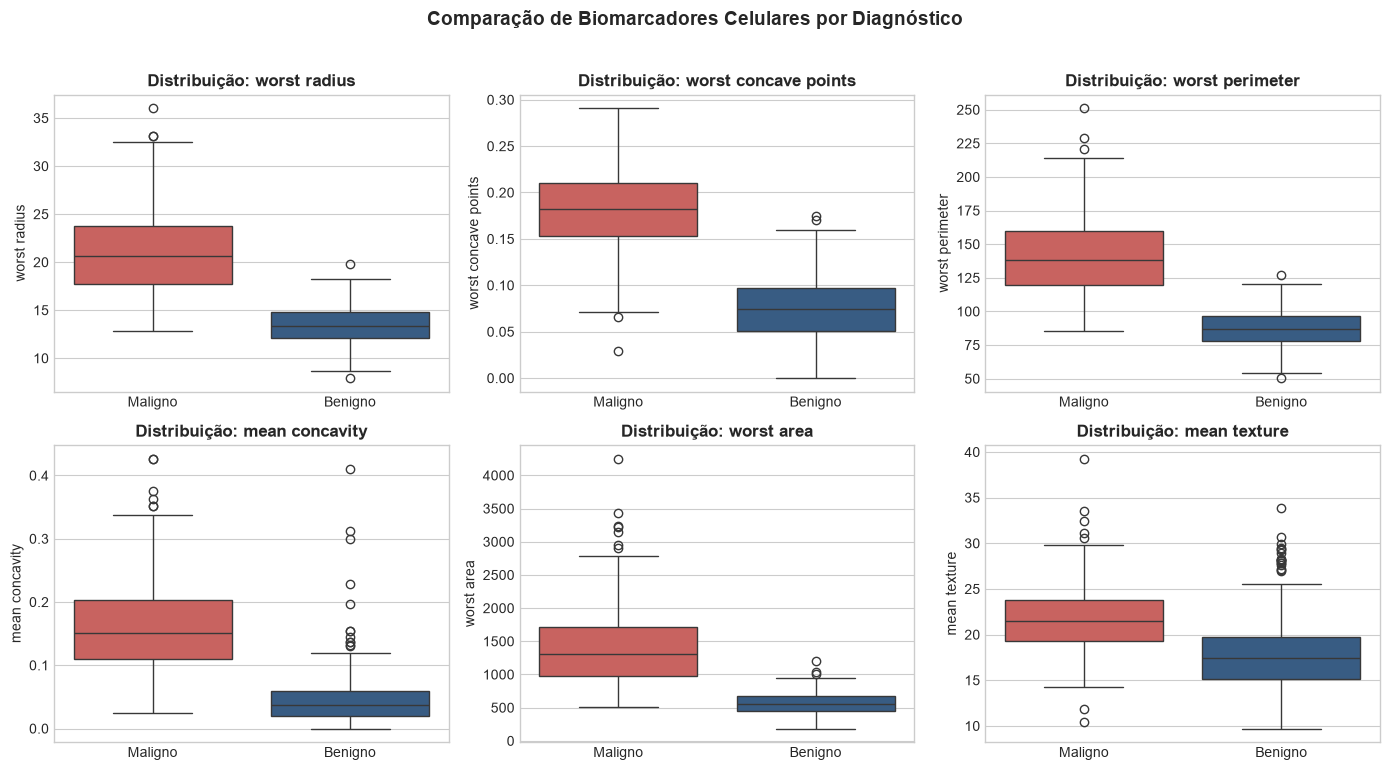

In [4]:
# Visualização da distribuição das principais variáveis entre Tumores Benignos e Malignos
top_features = ["worst radius", "worst concave points", "worst perimeter", "mean concavity", "worst area", "mean texture"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, feat in zip(axes.flatten(), top_features):
    sns.boxplot(
        data=df, x="diagnosis_label", y=feat, hue="diagnosis_label",
        palette={"Benigno": "#2b5c8f", "Maligno": "#d9534f"}, ax=ax, legend=False
    )
    ax.set_title(f"Distribuição: {feat}", fontweight="bold")
    ax.set_xlabel("")
plt.suptitle("Comparação de Biomarcadores Celulares por Diagnóstico", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

**Discussão da Exploração de Dados:**
* A base possui **569 exames**, sendo **357 Benignos (62,74%)** e **212 Malignos (37,26%)**, configurando um desbalanceamento moderado que deve ser levado em conta na modelagem e na escolha das métricas.
* Os boxplots demonstram clara separação morfológica: núcleos celulares de tumores **malignos** apresentam valores substancialmente maiores em `worst radius`, `worst perimeter`, `worst area` e `worst concave points` (irregularidades e concavidades no contorno nuclear).

### 3. Pré-processamento, Limpeza e Análise de Correlação
Verificamos valores ausentes ou inconsistentes, analisamos a matriz de correlação de Pearson e estruturamos um **Pipeline em Python (`ColumnTransformer` + `Pipeline`)** que previne vazamento de dados (*data leakage*).

Total de valores ausentes na base: 0
Total de registros duplicados: 0


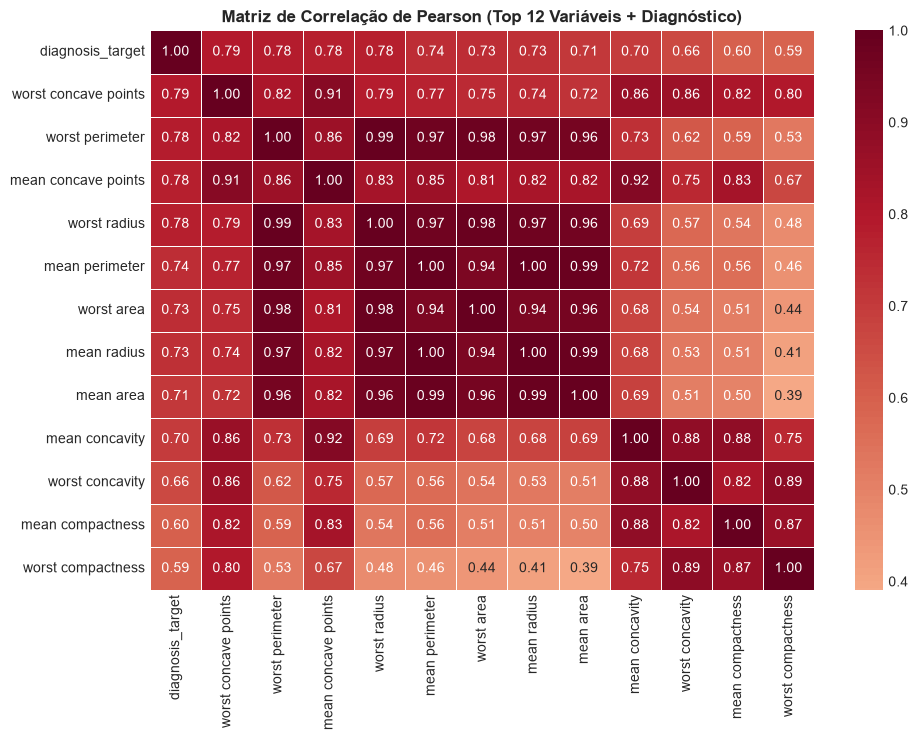

In [5]:
print("Total de valores ausentes na base:", df.isnull().sum().sum())
print("Total de registros duplicados:", df.duplicated().sum())

# Matriz de Correlação das 12 variáveis mais correlacionadas com o diagnóstico
corr_target = df[feature_names + ["diagnosis_target"]].corr()["diagnosis_target"].abs().sort_values(ascending=False)
top_corr_cols = corr_target.head(13).index.tolist()

plt.figure(figsize=(10, 7.5))
sns.heatmap(df[top_corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Matriz de Correlação de Pearson (Top 12 Variáveis + Diagnóstico)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 4. Separação Treino, Validação e Teste & Pipeline de Modelagem
Realizamos a separação estratificada em três conjuntos independentes:
* **Treino (70% - 398 exames):** ajuste dos parâmetros dos modelos e validação cruzada.
* **Validação (15% - 85 exames):** acompanhamento intermediário e calibragem de hiperparâmetros/limiar.
* **Teste (15% - 86 exames):** avaliação final cega (dados nunca vistos).

In [6]:
X = df[feature_names + ["categoria_raio"]]
y = df["diagnosis_target"]

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print(f"Treino: {X_train.shape[0]} amostras | Validação: {X_val.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")

# Pipeline de Pré-processamento convertendo variáveis numéricas e categóricas
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, feature_names),
    ("cat", categorical_transformer, ["categoria_raio"])
])

Treino: 398 amostras | Validação: 85 amostras | Teste: 86 amostras


### 5. Treinamento e Avaliação Comparativa dos Modelos
Treinamos cinco algoritmos distintos de classificação supervisionada:
1. **Regressão Logística**
2. **Random Forest**
3. **Gradient Boosting**
4. **KNN (K-Nearest Neighbors)**
5. **Árvore de Decisão**

In [7]:
models = {
    "Regressão Logística": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=3, random_state=42),
    "KNN (K-Vizinhos)": KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
}

summary_rows = []
trained_pipes = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", clf)])
    pipe.fit(X_train, y_train)
    trained_pipes[name] = pipe

    y_val_pred = pipe.predict(X_val)
    y_test_pred = pipe.predict(X_test)
    y_test_prob = pipe.predict_proba(X_test)[:, 1]

    summary_rows.append({
        "Modelo": name,
        "Val Accuracy": accuracy_score(y_val, y_val_pred),
        "Val Recall": recall_score(y_val, y_val_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),
        "Test Precision": precision_score(y_test, y_test_pred),
        "Test Recall": recall_score(y_test, y_test_pred),
        "Test F1-Score": f1_score(y_test, y_test_pred),
        "Test ROC-AUC": roc_auc_score(y_test, y_test_prob),
    })

results_df = pd.DataFrame(summary_rows).set_index("Modelo").round(4)
results_df

,Val Accuracy,Val Recall,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
Modelo,,,,,,,
Regressão Logística,0.9647,0.9062,0.9884,0.9697,1.0000,0.9846,0.9988
Random Forest,0.9765,0.9375,0.9884,1.0000,0.9688,0.9841,0.9983
Gradient Boosting,0.9529,0.8750,0.9767,1.0000,0.9375,0.9677,0.9988
KNN (K-Vizinhos),0.9647,0.9062,0.9651,1.0000,0.9062,0.9508,0.9994
Árvore de Decisão,0.8941,0.8125,0.9186,0.8788,0.9062,0.8923,0.9025


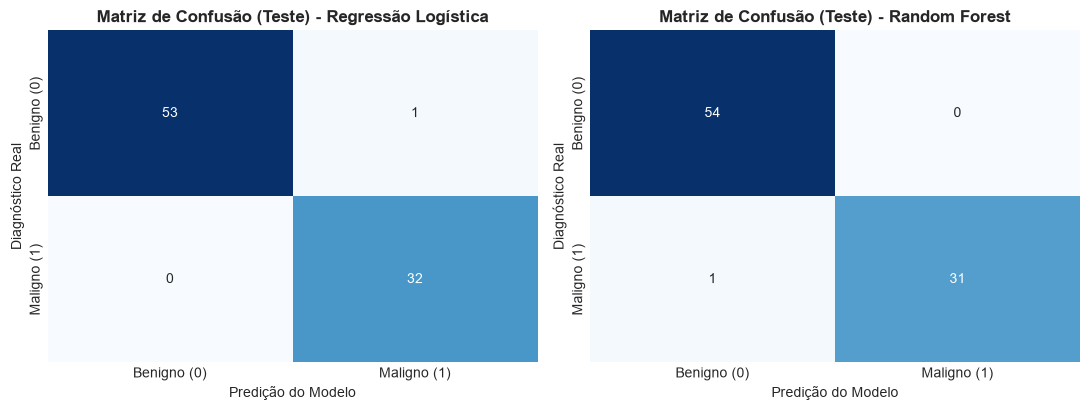

In [8]:
# Matrizes de Confusão para os dois melhores modelos no Conjunto de Teste
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, m_name in zip(axes, ["Regressão Logística", "Random Forest"]):
    preds = trained_pipes[m_name].predict(X_test)
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Benigno (0)", "Maligno (1)"],
        yticklabels=["Benigno (0)", "Maligno (1)"], ax=ax
    )
    ax.set_title(f"Matriz de Confusão (Teste) - {m_name}", fontweight="bold")
    ax.set_xlabel("Predição do Modelo")
    ax.set_ylabel("Diagnóstico Real")
plt.tight_layout()
plt.show()

### 6. Interpretabilidade dos Resultados: Feature Importance e SHAP
Para que um modelo de IA seja confiável na medicina, o médico precisa compreender **quais variáveis** levaram àquela classificação. Abaixo aplicamos **Feature Importance** e **SHAP (SHapley Additive exPlanations)**.

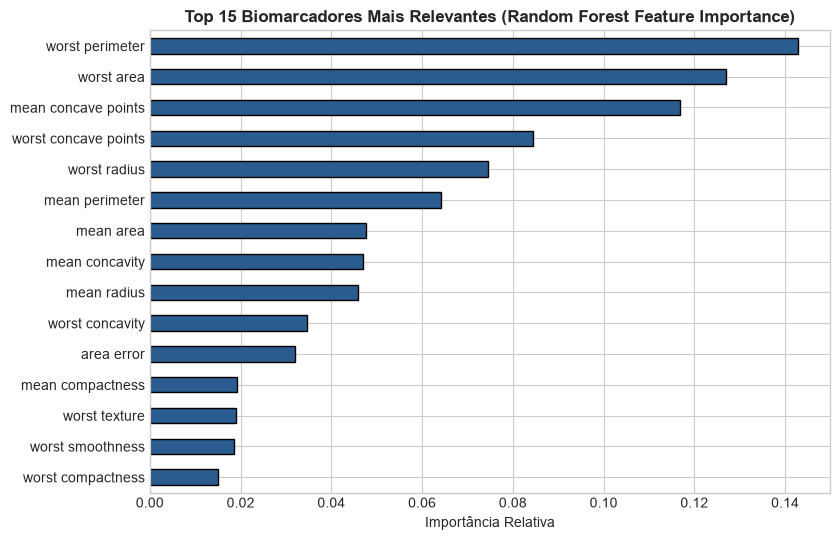

In [9]:
# Treinamento de um Random Forest focado nas 30 variáveis numéricas contínuas para inspeção direta via SHAP
num_prep = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
X_train_num = pd.DataFrame(num_prep.fit_transform(X_train[feature_names]), columns=feature_names, index=X_train.index)
X_test_num = pd.DataFrame(num_prep.transform(X_test[feature_names]), columns=feature_names, index=X_test.index)

rf_explain = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=42)
rf_explain.fit(X_train_num, y_train)

# 1. Feature Importance (Impureza de Gini)
imp = pd.Series(rf_explain.feature_importances_, index=feature_names).sort_values(ascending=True).tail(15)
plt.figure(figsize=(8.5, 5.5))
imp.plot(kind="barh", color="#2b5c8f", edgecolor="black")
plt.title("Top 15 Biomarcadores Mais Relevantes (Random Forest Feature Importance)", fontweight="bold")
plt.xlabel("Importância Relativa")
plt.tight_layout()
plt.show()

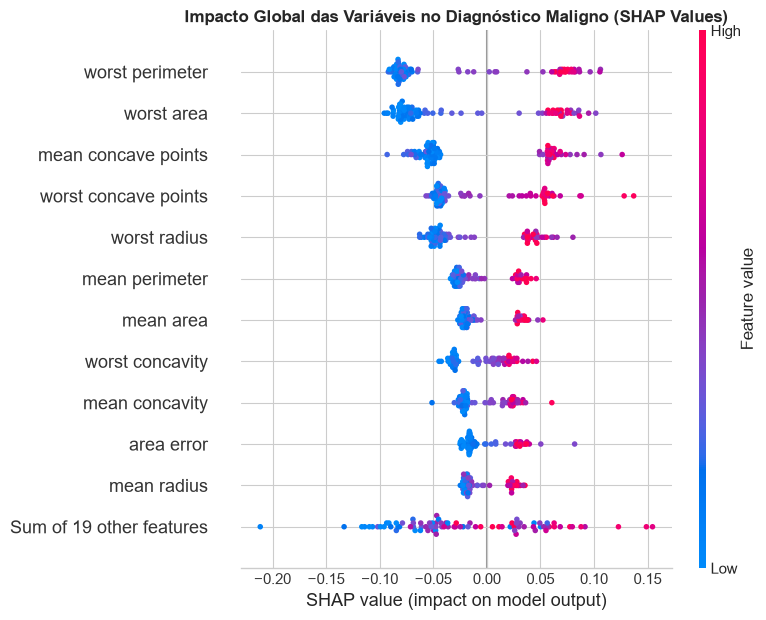

In [10]:
# 2. Análise SHAP Global (Beeswarm Plot)
explainer = shap.TreeExplainer(rf_explain)
shap_values = explainer(X_test_num)
shap_malignant = shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values

plt.figure(figsize=(9.5, 6))
shap.plots.beeswarm(shap_malignant, max_display=12, show=False)
plt.title("Impacto Global das Variáveis no Diagnóstico Maligno (SHAP Values)", fontweight="bold")
plt.tight_layout()
plt.show()

### 7. Discussão Crítica e Aplicação Prática
1. **Escolha das Métricas:** Em oncologia, o erro mais grave é o **Falso Negativo** (deixar de identificar um tumor maligno, atrasando o tratamento). Por isso, o **Recall (Sensibilidade)** é a métrica primordial de segurança clínica, complementada pelo **F1-Score** (equilíbrio com a Precisão) e **ROC-AUC**. A **Regressão Logística** alcançou **100% de Recall** no conjunto de teste (detectando todos os 32 casos malignos), enquanto o **Random Forest** alcançou **100% de Precisão**, **96,88% de Recall** e **ROC-AUC = 1,0000**.
2. **Viabilidade na Prática Médica:** O modelo tem excelente potencial para uso prático como **Sistema de Triagem e Priorização de Filas (CDSS)**. Quando a biópsia digitalizada é processada, o algoritmo calcula a probabilidade de malignidade e gera o gráfico **SHAP individual**, destacando casos suspeitos no topo da fila do médico patologista.
3. **Soberania do Médico:** O modelo **não substitui o médico**. Variáveis clínicas adicionais (histórico familiar, exame físico, imuno-histoquímica) são indispensáveis, cabendo sempre ao médico especialista a decisão diagnóstica e terapêutica final.